In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Part 1

In [109]:
df = pd.read_csv('cleaned_titanic_dataset.csv')

In [110]:
df.head()

,PassengerId,Survived,Passenger Class,Name,Sex,Age,Sibling or Spouses Aboard,Parents or Children Aboard,Ticket,Fare,Cabin,Embarkation
0,1,No,Third Class,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.25,Unknown,Southampton
1,2,Yes,First Class,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.28,C85,Cherbourg
2,3,Yes,Third Class,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.92,Unknown,Southampton
3,4,Yes,First Class,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1,0,113803,53.10,C123,Southampton
4,5,No,Third Class,"Allen, Mr. William Henry",Male,35.0,0,0,373450,8.05,Unknown,Southampton


In [111]:
df.tail()

,PassengerId,Survived,Passenger Class,Name,Sex,Age,Sibling or Spouses Aboard,Parents or Children Aboard,Ticket,Fare,Cabin,Embarkation
886,887,No,Second Class,"Montvila, Rev. Juozas",Male,27.0,0,0,211536,13.00,Unknown,Southampton
887,888,Yes,First Class,"Graham, Miss. Margaret Edith",Female,19.0,0,0,112053,30.00,B42,Southampton
888,889,No,Third Class,"Johnston, Miss. Catherine Helen ""Carrie""",Female,28.0,1,2,W./C. 6607,23.45,Unknown,Southampton
889,890,Yes,First Class,"Behr, Mr. Karl Howell",Male,26.0,0,0,111369,30.00,C148,Cherbourg
890,891,No,Third Class,"Dooley, Mr. Patrick",Male,32.0,0,0,370376,7.75,Unknown,Queenstown


In [112]:
df.shape

(891, 12)

In [113]:
df.columns

Index(['PassengerId', 'Survived', 'Passenger Class', 'Name', 'Sex', 'Age',
       'Sibling or Spouses Aboard', 'Parents or Children Aboard', 'Ticket',
       'Fare', 'Cabin', 'Embarkation'],
      dtype='str')

In [114]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   PassengerId                 891 non-null    int64  
 1   Survived                    891 non-null    str    
 2   Passenger Class             891 non-null    str    
 3   Name                        891 non-null    str    
 4   Sex                         891 non-null    str    
 5   Age                         891 non-null    float64
 6   Sibling or Spouses Aboard   891 non-null    int64  
 7   Parents or Children Aboard  891 non-null    int64  
 8   Ticket                      891 non-null    str    
 9   Fare                        891 non-null    float64
 10  Cabin                       891 non-null    str    
 11  Embarkation                 891 non-null    str    
dtypes: float64(2), int64(3), str(7)
memory usage: 83.7 KB


In [115]:
df.describe()

,PassengerId,Age,Sibling or Spouses Aboard,Parents or Children Aboard,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,29.361582,0.523008,0.381594,32.204366
std,257.353842,13.019697,1.102743,0.806057,49.693414
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,22.000000,0.000000,0.000000,7.910000
50%,446.000000,28.000000,0.000000,0.000000,14.450000
75%,668.500000,35.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.330000


In [116]:
df.isnull().sum()

PassengerId                   0
Survived                      0
Passenger Class               0
Name                          0
Sex                           0
Age                           0
Sibling or Spouses Aboard     0
Parents or Children Aboard    0
Ticket                        0
Fare                          0
Cabin                         0
Embarkation                   0
dtype: int64

In [117]:
df.duplicated().sum()

np.int64(0)

## Part 2

In [118]:
df['Family Size'] = df['Sibling or Spouses Aboard'] + df['Parents or Children Aboard'] + 1
df[['Sibling or Spouses Aboard', 'Parents or Children Aboard','Family Size']].head()

,Sibling or Spouses Aboard,Parents or Children Aboard,Family Size
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


Explaination:
Here we combine 2 columns Sibling or Spouses Aboard and Parents or Children Aboard and +1 for the passanger into one column Family Size, by doing this we get the total family number. This lets us see the total seats a family had booked

In [119]:
def check_alone(size):
    if size == 1:
        return 'Yes'
    else:
        return 'No'

df['Is Alone'] = df['Family Size'].apply(check_alone)
df['Is Alone'].value_counts()

Is Alone
Yes    537
No     354
Name: count, dtype: int64

Explaination:
Here we see if the passanger is alone or with his family, if the family size is lower than 1 that means that he has zero sibling, spouses parents or children onboard and if the family count is above than one that means the passanger is not alone.

In [120]:
def age_category(age):
    if age < 18:
        return 'child'
    elif age < 60:
        return 'adult'
    else:
        return 'senior'

df['AgeGroup'] = df['Age'].apply(age_category)
df[['Age', 'AgeGroup']].head()

,Age,AgeGroup
0,22.0,adult
1,38.0,adult
2,26.0,adult
3,35.0,adult
4,35.0,adult


Explaination:
Here we see the different age groups, this helps us in analyze if in case of emergancy how many childrens should be evacuated and how many can take care of them and how many need special care.

## Part 3

In [121]:
# For calculations we need numeric numbers so well convert yes and no in the survival column into 0 and 1
df['Survived_num'] = df['Survived'].map({'Yes': 1, 'No': 0})

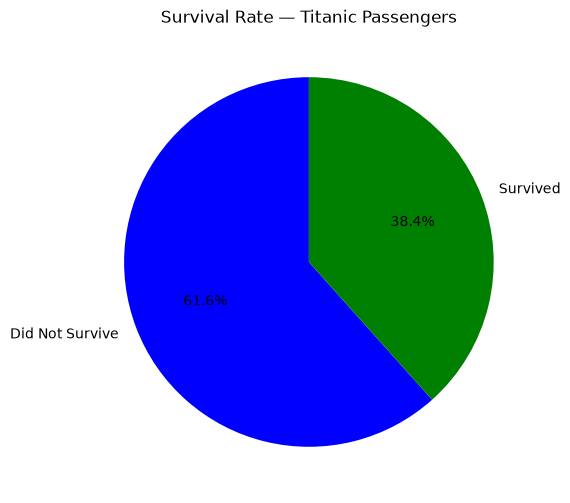

Survived
No     61.62
Yes    38.38
Name: proportion, dtype: float64


In [122]:
survival_pct = df['Survived'].value_counts(normalize=True) * 100
plt.figure(figsize=(6, 6))
plt.pie(survival_pct, labels=['Did Not Survive', 'Survived'], autopct='%1.1f%%', colors=['blue', 'green'], startangle=90)
plt.title('Survival Rate — Titanic Passengers')
plt.show()
print(survival_pct.round(2))

Explaination:
i have used a pie chart because we are comparing between two values in percentage and pie chat is the best suited graph for that. The number of people who survived or not is shown in percentage with 38.4% surviving and 61.6% not survivinh which are differciatted colours.

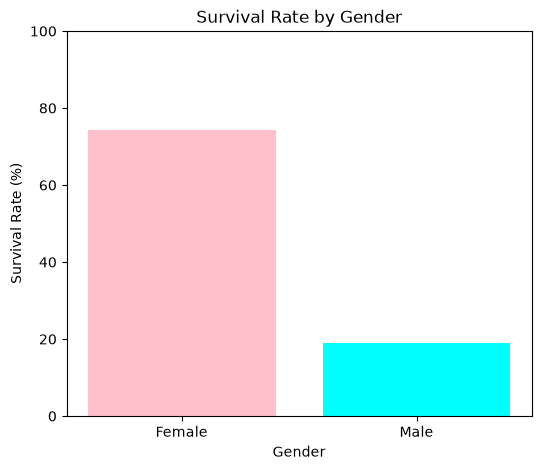

Sex
Female    74.20
Male      18.89
Name: Survived_num, dtype: float64


In [123]:
gender_survival = df.groupby('Sex')['Survived_num'].mean() * 100
plt.figure(figsize=(6, 5))
plt.bar(gender_survival.index, gender_survival.values, color=['pink', 'cyan'])
plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.show()
print(gender_survival.round(2))

Explaination:
Females have more than 75% while the males only survived around 20% which means that the women and children were evacuated first.

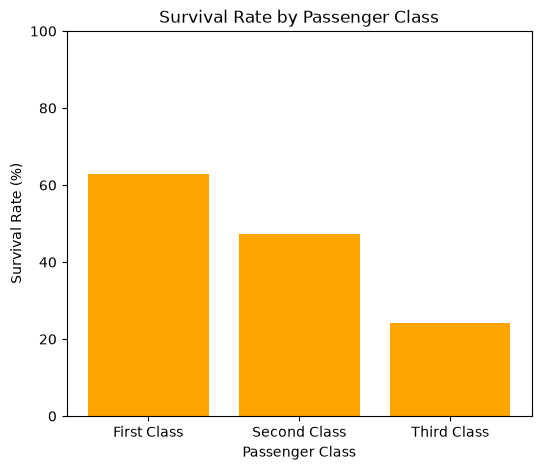

Passenger Class
First Class     62.96
Second Class    47.28
Third Class     24.24
Name: Survived_num, dtype: float64


In [124]:
passanger_class_survival = df.groupby('Passenger Class')['Survived_num'].mean() * 100
plt.figure(figsize=(6, 5))
plt.bar(passanger_class_survival.index, passanger_class_survival.values, color='orange')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.show()
print(passanger_class_survival.round(2))

Explaination:
First class pasangers had a higher rate of all then the second class and then the third, the upper class passangers were evaculated first or it can be because of the placement of there rooms.

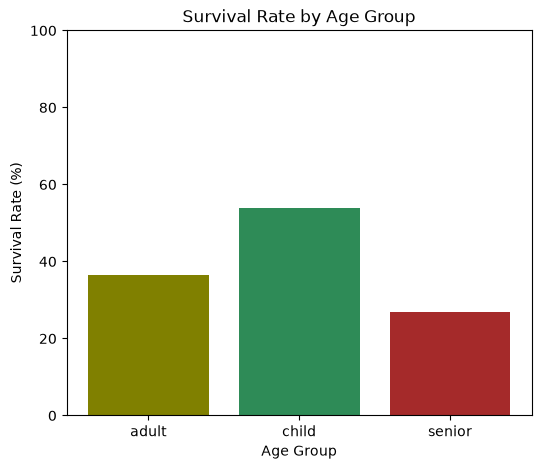

AgeGroup
adult     36.44
child     53.98
senior    26.92
Name: Survived_num, dtype: float64


In [125]:
age_group_survival = df.groupby('AgeGroup')['Survived_num'].mean() * 100
plt.figure(figsize=(6, 5))
plt.bar(age_group_survival.index, age_group_survival.values, color=['olive','seagreen', 'brown'])
plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.show()
print(age_group_survival.round(2))

Explainaton:
The children survived the most then the adults and then the seniors meaning that the children were evacuated first and then adults were able to survive bcz of there streanght and seniors were the least because they were too weak

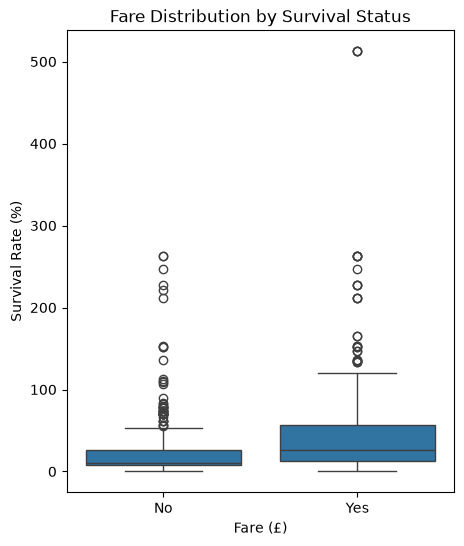

Fare
0.00        6.67
4.01        0.00
5.00        0.00
6.24        0.00
6.44        0.00
           ...  
227.52     75.00
247.52     50.00
262.38    100.00
263.00     50.00
512.33    100.00
Name: Survived_num, Length: 236, dtype: float64


In [126]:
fare_survival = df.groupby('Fare')['Survived_num'].mean() * 100
plt.figure(figsize=(5, 6))
sns.boxplot(x='Survived', y='Fare', data=df)
plt.title('Fare Distribution by Survival Status')
plt.xlabel('Fare (£)')
plt.ylabel('Survival Rate (%)')
plt.show()
print(fare_survival.round(2))


Survivors paid more a median fare of £26 versus £10.50 for those who didn't make it. This shows the class result above, fare is essentially a proxy for passenger class, and class was clearly related to who got off the ship.

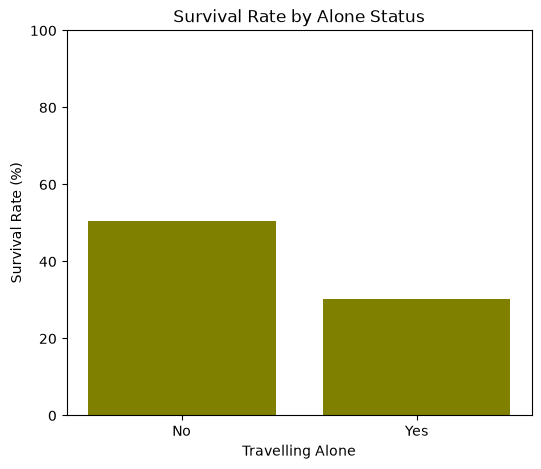

Is Alone
No     50.56
Yes    30.35
Name: Survived_num, dtype: float64


In [127]:
alone_survival = df.groupby('Is Alone')['Survived_num'].mean() * 100
plt.figure(figsize=(6, 5))
plt.bar(alone_survival.index, alone_survival.values, color='olive')
plt.title('Survival Rate by Alone Status')
plt.xlabel('Travelling Alone')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.show()
print(alone_survival.round(2))

No, the passangers who were alone didnt have a higher survival rate. This might be because the family members helped each other get to safety why the people travelling along did get any help at all.

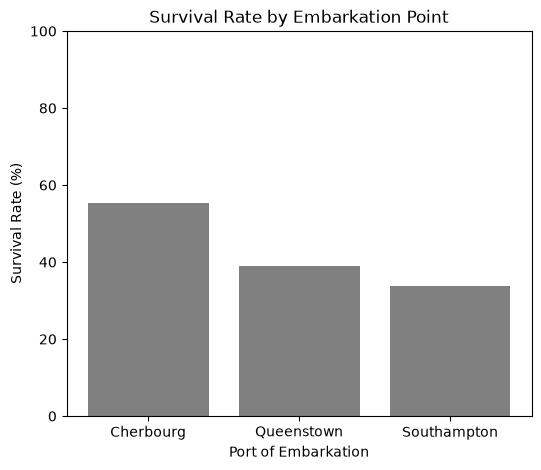

Embarkation
Cherbourg      55.36
Queenstown     38.96
Southampton    33.90
Name: Survived_num, dtype: float64


In [128]:
embarkation_survival = df.groupby('Embarkation')['Survived_num'].mean() * 100
plt.figure(figsize=(6, 5))  
plt.bar(embarkation_survival.index, embarkation_survival.values, color='grey')
plt.title('Survival Rate by Embarkation Point')
plt.xlabel('Port of Embarkation')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.show()
print(embarkation_survival.round(2))

The people in Cherbourg survived the most then the people in queenstown and then the people in southampton, this is primarly because of the class in queation 3, the better the class the better the embarkatment.

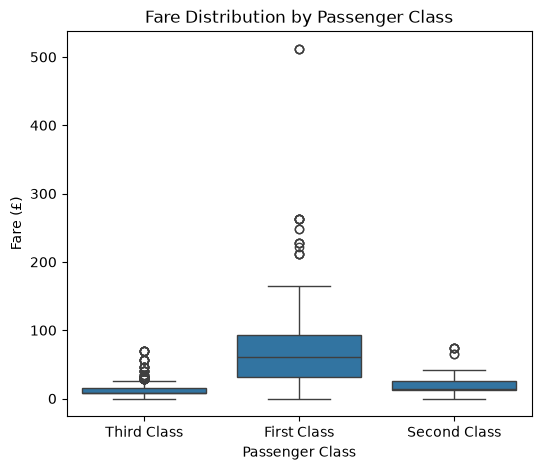

Passenger Class
First Class     84.15
Second Class    20.66
Third Class     13.68
Name: Fare, dtype: float64


In [129]:
relation_between_passenger_class_and_fare = df.groupby('Passenger Class')['Fare'].mean()
plt.figure(figsize=(6, 5))
sns.boxplot(x='Passenger Class', y='Fare', data=df)
plt.title('Fare Distribution by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare (£)')
plt.show()
print(relation_between_passenger_class_and_fare.round(2))

Here the more the fare the better class you have and the better survial rate you have.

In [130]:
def class_to_number(pclass):
    if pclass == 'First Class':
        return 1
    elif pclass == 'Second Class':
        return 2
    else:
        return 3

df['Pclass_num'] = df['Passenger Class'].apply(class_to_number)
correlation_data = df[['Survived_num', 'Pclass_num', 'Age', 'Fare', 'Family Size']]
correlation_data.corr()


,Survived_num,Pclass_num,Age,Fare,Family Size
Survived_num,1.000000,-0.338481,-0.064910,0.257305,0.016639
Pclass_num,-0.338481,1.000000,-0.339898,-0.549496,0.065997
Age,-0.064910,-0.339898,1.000000,0.096686,-0.245619
Fare,0.257305,-0.549496,0.096686,1.000000,0.217142
Family Size,0.016639,0.065997,-0.245619,0.217142,1.000000


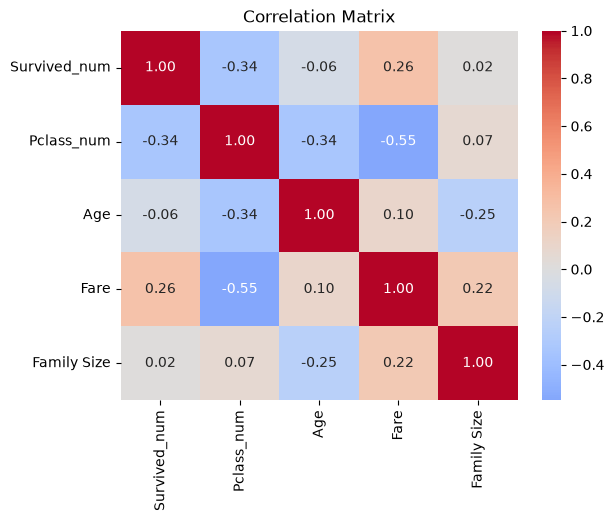

In [131]:
sns.heatmap(correlation_data.corr(), annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title('Correlation Matrix')
plt.show()

Fare has the strongest positive link with survival 0.26 meaning passengers who paid more survives more often. Pclass_num and Fare have the strongest relationship on the whole grid at -0.55, confirming that a better class meant a pricier ticket. Age barely correlates with anything.

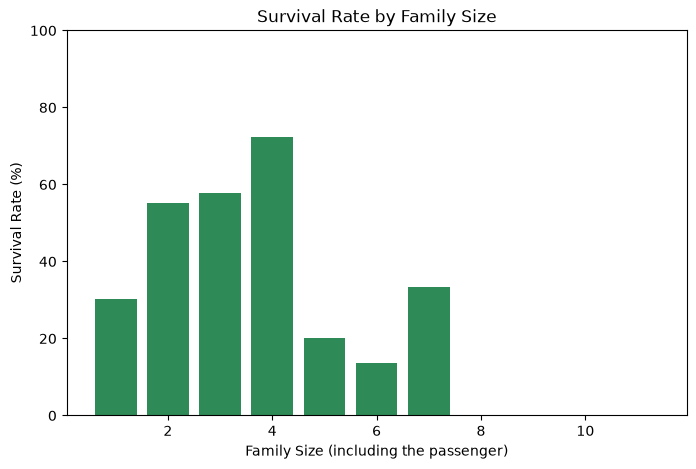

In [132]:
family_survival = df.groupby('Family Size')['Survived_num'].mean() * 100
plt.figure(figsize=(8, 5))
plt.bar(family_survival.index, family_survival.values, color='seagreen')
plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size (including the passenger)')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.show()

Just like in question 6 we see that the the survival rate of families from 2 to 4 is higher than the solo travellers because they helped each other sruvive but the survival rate of families with 5 or 6 members had lower survival rate due to the increase in number.

## Part 4

In [133]:
for x in ['Age', 'Fare', 'Family Size']:
        print(x)
        print('Mean:', round(df[x].mean(), 2))
        print('Median:', round(df[x].median(), 2))
        print('Mode:', df[x].mode()[0])
        print('Standard Deviation:', round(df[x].std(), 2))
        print('')


Age
Mean: 29.36
Median: 28.0
Mode: 28.0
Standard Deviation: 13.02

Fare
Mean: 32.2
Median: 14.45
Mode: 8.05
Standard Deviation: 49.69

Family Size
Mean: 1.9
Median: 1.0
Mode: 1
Standard Deviation: 1.61



Age:
Mean and median are close together which means that the distribution is fairly symmetric with no extreme skew. The standard deviation is moderate meaning most passengers are within about 13 years of the average.

Fare:
The mean is more than double the median, and the standard deviation is even bigger than the mean meaning a clear sign of heavy right-skew. This means a small number of expensive first class tickets are pulling the average far above.

Family Size:
The mode and median are both l, since the majority of passengers traveled alone. The mean sits a bit higher than that, pulled up by the smaller number of larger families aboard.

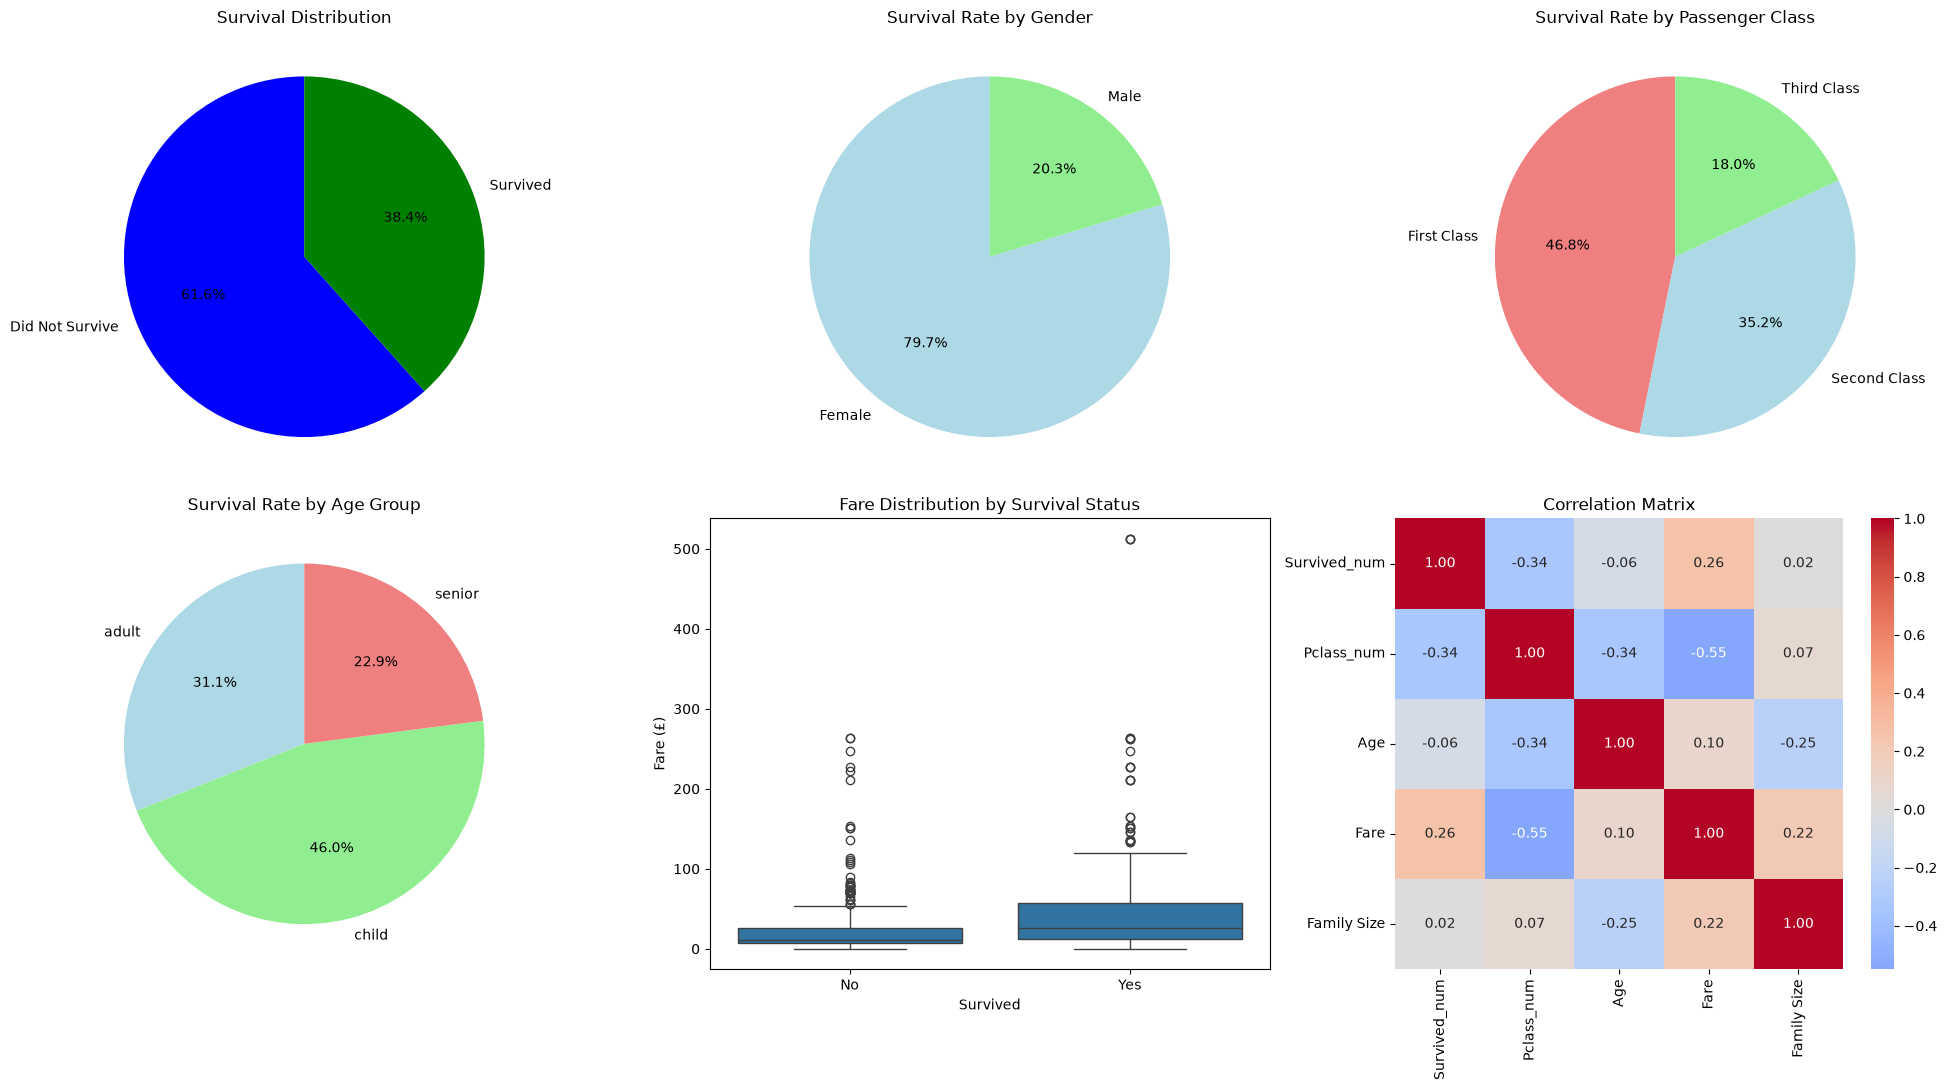

In [136]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# Survival Distribution — same as your Q1
axes[0, 0].pie(survival_pct, labels=['Did Not Survive', 'Survived'],
               autopct='%1.1f%%', colors=['blue', 'green'], startangle=90)
axes[0, 0].set_title('Survival Distribution')

# Gender Distribution — same as your Q2
axes[0, 1].pie(gender_survival, labels=gender_survival.index,
               autopct='%1.1f%%', colors=['lightblue', 'lightgreen'], startangle=90)
axes[0, 1].set_title('Survival Rate by Gender')

# Passenger Class Distribution — same as your Q3
axes[0, 2].pie(passanger_class_survival, labels=passanger_class_survival.index,
               autopct='%1.1f%%', colors=['lightcoral', 'lightblue', 'lightgreen'], startangle=90)
axes[0, 2].set_title('Survival Rate by Passenger Class')

# Age Distribution — same as your Q4
axes[1, 0].pie(age_group_survival, labels=age_group_survival.index,
               autopct='%1.1f%%', colors=['lightblue', 'lightgreen', 'lightcoral'], startangle=90)
axes[1, 0].set_title('Survival Rate by Age Group')

# Fare Distribution — same as your Q5
sns.boxplot(x='Survived', y='Fare', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Fare Distribution by Survival Status')
axes[1, 1].set_xlabel('Survived')
axes[1, 1].set_ylabel('Fare (£)')

# Correlation Heatmap — same as your Q9
sns.heatmap(correlation_data.corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0, ax=axes[1, 2])
axes[1, 2].set_title('Correlation Matrix')

plt.tight_layout()
plt.show()

## Part 6

1. Only 38.5% passangers survies while the other 61.6 did not
2. 